# FLIC leftover-mass estimation: reproduction + research extensions

**Base paper:** Piccoli et al., *FLIC: A Real-World Dataset for Visual Estimation of Food Leftovers in Canteens*, Appl. Sci. 2026, 16, 5465.

The paper is a *dataset* paper. Its baseline ("digital density") is deliberately simple, and its own future-work section names the open problems. This notebook turns those into testable research questions.

| ID | Research question | Where |
|---|---|---|
| RQ0 | Can the published baseline (Tables 3-6) be reproduced? | Section 6 |
| RQ1 | How much does the area-to-mass density shift between full and leftover plates, and does it explain the large errors (chicken with bone, pasta with vegetables)? | Section 7 |
| RQ2 | How much does it help to weigh a few *leftover* plates during enrollment, not only full ones? | Section 8 |
| RQ3 | Does using the **paired before/after image** (fraction of the serving remaining) beat area alone under few-shot enrollment? | Section 9 |
| RQ4 | Can the broad course class be assigned automatically (removing the human operator), and what is the downstream cost? | Section 10 |
| RQ5 | Can we give leftover-mass **prediction intervals with measured coverage**? | Section 11 |

**Design rules (so the results are defensible)**
- The paper's protocol is reproduced *first*, before anything new is claimed.
- New methods have at most **one** tuned hyperparameter, tuned on *development days only* and evaluated on *held-out days*, repeated over many random day splits.
- All splits are by **day**, because the same dish and the same tray session repeat within a day.
- Negative results are reported as they are. "The paired estimator does not help, and here is why" is still a valid finding.

**How to use**
1. Put the FLIC files in one folder (default `FLIC/`): `FLIC_grams.csv`, `FLIC_menu.csv` and the four zips (`full_images`, `left_images`, `full_masks`, `left_masks`). The notebook unzips them itself.
2. `DATA_MODE = 'real'` (default) runs on FLIC with `ROUTE = 'FLIC'`. Set `DATA_MODE = 'synthetic'` for a pipeline self-test on fake data, whose numbers must **never** be reported.

**Runtime:** about 3-8 minutes on CPU (most of it reading 802 images and masks). No GPU needed.

In [1]:
import sys, subprocess, importlib, warnings, json, math, time, os, platform, re
from pathlib import Path


def _ensure(pkg, imp=None):
    try:
        importlib.import_module(imp or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])


for _p, _i in [("numpy", None), ("pandas", None), ("scipy", None),
               ("scikit-learn", "sklearn"), ("matplotlib", None), ("pillow", "PIL")]:
    _ensure(_p, _i)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from PIL import Image
from scipy import ndimage, stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

SEED = 42
np.random.seed(SEED)
COURSES = ["first", "second", "side", "bread"]
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except Exception:
    IN_COLAB = False
print("Colab:", IN_COLAB, "| Python", platform.python_version(),
      "| numpy", np.__version__, "| pandas", pd.__version__)

Colab: False | Python 3.12.3 | numpy 2.5.4 | pandas 3.0.6


## 1. Configuration

Edit only this cell. Defaults run the synthetic self-test.

For **real FLIC data** there are three routes:

- **Route FLIC (default):** use the files exactly as distributed (`FLIC_grams.csv`, `FLIC_menu.csv`, four zips). The notebook reads the RGB masks directly, maps the colours of the paper's Figure 4 to courses, takes masses from the CSV and dish names from the menu, and cross-checks mask areas against the CSV pixel columns. Enables RQ4.
- **Route A (simplest):** you build one `items.csv` yourself, with one row per `(tray, course)` and these columns:
  `tray_id, day_id, course, area_full, area_left, mass_full, mass_left` (+ optional `fine_class, mixed`).
  Areas are food pixels of that course in the full / leftover image. Masses are grams (tare already subtracted). `course` is one of `first, second, side, bread`.
- **Route B (notebook computes the areas from the masks):** you provide
  - `manifest.csv`: `tray_id, day_id, state, image_path, mask_path` where `state` is `full` or `leftover`;
  - `masses.csv`: `tray_id, state, course, mass_g` (+ optional `fine_class, mixed`);
  - `MASK_LABELS`: which integer value in the mask PNGs means which course. Section 3 shows you the values present in your masks.

Route B also enables RQ4 (automatic course classification), which needs the images and masks.

In [2]:
# ===================== CONFIGURATION =====================
DATA_MODE = "real"             # "real" = FLIC | "synthetic" = pipeline self-test

# ---- synthetic mode ----
SYN_ROOT = Path("FLIC_synthetic")

# ---- real mode ----
REAL_ROOT = Path("FLIC")       # folder with FLIC_grams.csv, FLIC_menu.csv and the four zips
                               # (Colab + Drive: Path("/content/drive/MyDrive/FLIC"))
ROUTE = "FLIC"                 # "FLIC" (native files) | "A" (items.csv) | "B" (manifest + masses + masks)
MIXED_FROM = "2024-07-22"      # FLIC: from this date, a tray with side mass 0 is a mixed plate (paper: 111 trays)
ITEMS_CSV = REAL_ROOT / "items.csv"
MANIFEST_CSV = REAL_ROOT / "manifest.csv"
MASSES_CSV = REAL_ROOT / "masses.csv"

# integer value in the mask image -> (course, fine_class or None). Check with Section 3 first!
MASK_LABELS = {1: ("first", None), 2: ("second", None), 3: ("side", None),
               4: ("bread", None), 5: ("generic", None)}
MASK_BACKGROUND_IDS = (0,)
# FLIC masks are RGB; colours follow the paper's Figure 4 (blue first, magenta second, teal side, yellow bread)
MASK_RGB_TO_ID = {(50, 183, 250): 1, (184, 61, 245): 2, (170, 240, 209): 3, (250, 250, 55): 4}
MIXED_DAYS = []                # day_ids where second course + side share one plate (paper: last 5 days)

# ---- experiment budget (paper uses R = 100 runs) ----
R_REPRO = 100                  # runs for the reproduction tables
R_NEW = 50                     # runs for the new-method experiments
N_DAY_SPLITS = 10              # repeated dev/test day splits (RQ3)
N_CONFORMAL_SPLITS = 100       # repeated day splits (RQ5)
MIN_REGION_PX = 150            # ignore tiny connected components (RQ4)
OUTPUT_DIR = Path("flic_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
RESULTS = {}                   # every table is stored here and saved at the end
print("Mode:", DATA_MODE)

Mode: real


## 2. Synthetic data generator (pipeline self-test only)

This creates a *fake* canteen dataset with the same structure as Route B: 401 trays over 22 days, four plates per tray, class-index masks, full and leftover states, and the last 5 days flagged as "mixed". Some dishes deliberately change density between full and leftover, so the experiments have something to find. **It exists only so you can verify the code runs. Its numbers mean nothing.**

In [3]:
def read_mask_ids(path):
    """Read a mask image as an integer array of class ids."""
    im = Image.open(path)
    if im.mode in ("RGB", "RGBA"):
        if not MASK_RGB_TO_ID:
            raise ValueError("RGB mask found. Fill MASK_RGB_TO_ID = {(r,g,b): id, ...} in the config cell.")
        arr = np.array(im.convert("RGB"))
        out = np.zeros(arr.shape[:2], np.int32)
        for rgb, i in MASK_RGB_TO_ID.items():
            out[(arr == np.array(rgb, dtype=arr.dtype)).all(-1)] = i
        return out
    return np.array(im).astype(np.int32)


def _disk(shape, cx, cy, r):
    H, W = shape
    y0, y1 = max(0, int(cy - r) - 1), min(H, int(cy + r) + 2)
    x0, x1 = max(0, int(cx - r) - 1), min(W, int(cx + r) + 2)
    yy, xx = np.ogrid[y0:y1, x0:x1]
    return (slice(y0, y1), slice(x0, x1)), ((xx - cx) ** 2 + (yy - cy) ** 2 <= r * r)


def make_synthetic(root, seed=0, n_trays=401, n_days=22, n_mixed_days=5, size=(640, 480)):
    rng = np.random.default_rng(seed)
    W, H = size
    root = Path(root)
    (root / "images").mkdir(parents=True, exist_ok=True)
    (root / "masks").mkdir(parents=True, exist_ok=True)
    n_dish = 17

    def dish_table(lo, hi, offset_frac):
        t = []
        for _ in range(n_dish):
            shift = rng.uniform(0.45, 0.75) if rng.random() < 0.3 else rng.uniform(0.95, 1.05)
            off = rng.uniform(8, 25) if rng.random() < offset_frac else 0.0
            t.append(dict(dens=rng.uniform(lo, hi), shift=shift, off=off,
                          color=rng.integers(40, 230, 3)))
        return t

    first, second = dish_table(0.008, 0.015, 0.0), dish_table(0.006, 0.02, 0.25)
    side = dict(dens=0.007, shift=0.9, off=0.0, color=np.array([60, 160, 70]))
    bread = dict(dens=0.0065, shift=1.0, off=0.0, color=np.array([200, 160, 90]))
    tray_cols = [(205, 80, 40), (40, 140, 80), (215, 200, 60), (50, 80, 170)]
    slots = [(170, 130), (470, 130), (170, 355), (470, 355)]
    ids = {"first": 1, "second": 2, "side": 3, "bread": 4}
    day_groups = np.array_split(np.arange(n_trays), n_days)
    man, mas = [], []

    def render(slot_of, radius, tcol, dishes):
        img = np.clip(np.array(tcol)[None, None, :] + rng.normal(0, 5, (H, W, 3)), 0, 255).astype(np.uint8)
        mask = np.zeros((H, W), np.uint8)
        areas = {}
        for c in COURSES:
            cx, cy = slot_of[c]
            sl, m = _disk((H, W), cx, cy, 100)
            img[sl][m] = (235, 235, 235)
            r = radius[c]
            if r <= 0:
                areas[c] = 0
                continue
            sl, m = _disk((H, W), cx + rng.integers(-8, 9), cy + rng.integers(-8, 9), r)
            col = np.clip(dishes[c]["color"][None, :] + rng.normal(0, 12, (int(m.sum()), 3)), 0, 255)
            tmp = img[sl]
            tmp[m] = col.astype(np.uint8)
            mask[sl][m] = ids[c]
            areas[c] = int(m.sum())
        return img, mask, areas

    for d, tray_ids in enumerate(day_groups):
        f_id, s_id = d % n_dish, (d * 5 + 3) % n_dish
        dishes = {"first": first[f_id], "second": second[s_id], "side": side, "bread": bread}
        fine = {"first": f"First dish {f_id:02d}", "second": f"Second dish {s_id:02d}",
                "side": "side", "bread": "bread"}
        mixed = d >= n_days - n_mixed_days
        for t in tray_ids:
            tid = f"T{t:04d}"
            tcol = tray_cols[rng.integers(4)]
            slot_full = dict(zip(COURSES, [slots[i] for i in rng.permutation(4)]))
            slot_left = slot_full if rng.random() < 0.7 else dict(zip(COURSES, [slots[i] for i in rng.permutation(4)]))
            tgt = {"first": rng.uniform(9000, 22000), "second": rng.uniform(5000, 16000),
                   "side": rng.uniform(4000, 13000), "bread": np.pi * 50 ** 2}
            r_full = {c: min(92, math.sqrt(a / math.pi)) for c, a in tgt.items()}
            img_f, mask_f, a_f = render(slot_full, r_full, tcol, dishes)
            rem = {}
            for c in COURSES:
                q = rng.beta(1.1, 5) if rng.random() < 0.8 else rng.beta(3, 2)
                rem[c] = math.sqrt(max(q * a_f[c], 0) / math.pi)
                if rem[c] < 6:
                    rem[c] = 0
            img_l, mask_l, a_l = render(slot_left, rem, tcol, dishes)
            for state, img, mask, areas in [("full", img_f, mask_f, a_f), ("leftover", img_l, mask_l, a_l)]:
                ip, mp = f"images/{tid}_{state}.png", f"masks/{tid}_{state}.png"
                Image.fromarray(img).save(root / ip)
                Image.fromarray(mask).save(root / mp)
                man.append(dict(tray_id=tid, day_id=f"D{d:02d}", state=state, image_path=ip, mask_path=mp))
                for c in COURSES:
                    p = dishes[c]
                    if state == "full":
                        mass = 50.0 if c == "bread" else p["dens"] * areas[c] * rng.normal(1, 0.10)
                    else:
                        mass = p["dens"] * p["shift"] * areas[c] * rng.normal(1, 0.15) + (p["off"] if areas[c] > 0 else 0)
                    mas.append(dict(tray_id=tid, state=state, course=c, mass_g=round(max(mass, 0), 1),
                                    fine_class=fine[c], mixed=mixed))
    manifest, masses = pd.DataFrame(man), pd.DataFrame(mas)
    manifest.to_csv(root / "manifest.csv", index=False)
    masses.to_csv(root / "masses.csv", index=False)
    return manifest, masses


if DATA_MODE == "synthetic":
    t0 = time.time()
    if not (SYN_ROOT / "manifest.csv").exists():
        make_synthetic(SYN_ROOT)
    print(f"Synthetic dataset ready in {SYN_ROOT} ({time.time() - t0:.0f}s)")
    print("WARNING: SYNTHETIC DATA. Use only to test the pipeline. Do not report any number below.")
else:
    print("Skipped (real mode).")

Skipped (real mode).


## 3. Inspect the real dataset (real mode only)

Run this *before* filling `MASK_LABELS`. It lists file types, shows CSV columns, and prints the distinct integer values found in a few mask files. Map those values to courses in the config cell.

In [4]:
def inspect_real(root, n_masks=4):
    root = Path(root)
    if IN_COLAB and str(root).startswith("/content/drive") and not root.exists():
        from google.colab import drive
        drive.mount("/content/drive")
    files = [p for p in root.rglob("*") if p.is_file()]
    print("Total files:", len(files))
    print(pd.Series([p.suffix.lower() for p in files]).value_counts().to_string())
    for p in [p for p in files if p.suffix.lower() in {".csv", ".tsv", ".xlsx"}][:10]:
        try:
            df = pd.read_excel(p, nrows=3) if p.suffix.lower() == ".xlsx" else pd.read_csv(p, nrows=3, sep=None, engine="python")
            print("\n###", p.relative_to(root), "| columns:", list(df.columns))
            print(df.to_string())
        except Exception as e:
            print("Could not read", p.name, repr(e))
    maskish = [p for p in files if p.suffix.lower() in IMG_EXT and re.search("mask|label|seg|annot", str(p).lower())]
    print("\nImages that look like masks:", len(maskish))
    for p in maskish[:n_masks]:
        try:
            print(p.relative_to(root), "-> distinct values:", np.unique(read_mask_ids(p))[:40])
        except Exception as e:
            print(p.name, "->", repr(e))


if DATA_MODE == "real":
    inspect_real(REAL_ROOT)
else:
    print("Skipped (synthetic mode).")

Total files: 1610
.png    1604
.zip       4
.csv       2

### FLIC_grams.csv | columns: ['Filename_full', 'Filename_left', 'Date', 'QR_code', 'First_full_grams', 'Second_gull_grams', 'Side_full_grams', 'Bread_full_grams', 'First_left_grams', 'Second_left_grams', 'Side_left_grams', 'Bread_left_grams', 'First_full_pixels', 'Second_gull_pixels', 'Side_full_pixels', 'Bread_full_pixels', 'First_left_pixels', 'Second_left_pixels', 'Side_left_pixels', 'Bread_left_pixels']
             Filename_full             Filename_left        Date  QR_code  First_full_grams  Second_gull_grams  Side_full_grams  Bread_full_grams  First_left_grams  Second_left_grams  Side_left_grams  Bread_left_grams  First_full_pixels  Second_gull_pixels  Side_full_pixels  Bread_full_pixels  First_left_pixels  Second_left_pixels  Side_left_pixels  Bread_left_pixels
0  2024-06-27_1201_pre.png  2024-06-27_1201_post.png  2024-06-27     1201               160                143               59                50               

## 4. Build the analysis tables

Two tables are produced:

- **`ITEMS`**: one row per `(tray, course)` with areas and masses in both states. This is the unit the paper evaluates.
- **`REGIONS`** (Route B only): one row per connected food region with simple shape, position, and colour features, used for RQ4.

Items flagged as **mixed** (second course and side dish on the same plate) are excluded from the analysis set, as in the paper. On those trays the first course and the bread stay usable, which is how the paper reaches 1,166 items. For RQ4 (region classification) the whole mixed tray is excluded, because a merged second+side region has no single true class.

In [5]:
def region_features(img, lab, k, sl, W, H):
    sub = lab[sl] == k
    ys, xs = np.nonzero(sub)
    area = int(sub.sum())
    pix = img[sl][sub].astype(float)
    hsv = mcolors.rgb_to_hsv(pix / 255.0)
    bw, bh = sl[1].stop - sl[1].start, sl[0].stop - sl[0].start
    cx = (xs.mean() + sl[1].start) / W
    cy = (ys.mean() + sl[0].start) / H
    hue = hsv[:, 0] * 2 * np.pi
    return dict(area_px=area, area_frac=area / (W * H), cx=cx, cy=cy, bw=bw / W, bh=bh / H,
                extent=area / max(bw * bh, 1),
                mR=pix[:, 0].mean(), mG=pix[:, 1].mean(), mB=pix[:, 2].mean(),
                sR=pix[:, 0].std(), sG=pix[:, 1].std(), sB=pix[:, 2].std(),
                mS=hsv[:, 1].mean(), mV=hsv[:, 2].mean(), sS=hsv[:, 1].std(), sV=hsv[:, 2].std(),
                hcos=np.cos(hue).mean(), hsin=np.sin(hue).mean())


def build_tables_from_masks(manifest, masses, root, labels, bg_ids, mixed_days=()):
    root = Path(root)
    manifest, masses = manifest.copy(), masses.copy()
    for df_ in (manifest, masses):
        df_["tray_id"] = df_["tray_id"].astype(str).str.strip()
        df_["state"] = df_["state"].astype(str).str.lower().str.strip()
    manifest["day_id"] = manifest["day_id"].astype(str)
    masses["course"] = masses["course"].astype(str).str.lower().str.strip()
    bad_states = set(manifest.state) | set(masses.state)
    if not bad_states <= {"full", "leftover"}:
        raise ValueError(f"state must be 'full' or 'leftover'; found {sorted(bad_states)}")
    mixed_days = [str(d) for d in mixed_days]
    id2course = {i: v[0] for i, v in labels.items() if v[0] in COURSES}
    id2fine = {i: (v[0], v[1]) for i, v in labels.items() if v[0] in COURSES and v[1]}
    area_rows, region_rows, fine_rows = [], [], []

    def rp(x):
        p = Path(str(x))
        return p if p.is_absolute() else root / p

    for r in manifest.itertuples(index=False):
        ids = read_mask_ids(rp(r.mask_path))
        H, W = ids.shape
        for c in COURSES:
            sel = [i for i, cc in id2course.items() if cc == c]
            area_rows.append((r.tray_id, r.state, c, int(np.isin(ids, sel).sum())))
        if id2fine and r.state == "full":
            for c in ("first", "second"):
                cand = {i: int((ids == i).sum()) for i, (cc, _) in id2fine.items() if cc == c}
                if cand and max(cand.values()) > 0:
                    best = max(cand, key=cand.get)
                    fine_rows.append((r.tray_id, c, id2fine[best][1]))
        img = np.array(Image.open(rp(r.image_path)).convert("RGB"))
        if img.shape[:2] != (H, W):
            img = np.array(Image.fromarray(img).resize((W, H)))
        food = ~np.isin(ids, bg_ids)
        lab, n = ndimage.label(food)
        for k, sl in enumerate(ndimage.find_objects(lab), start=1):
            if sl is None or (lab[sl] == k).sum() < MIN_REGION_PX:
                continue
            f = region_features(img, lab, k, sl, W, H)
            member = ids[sl][lab[sl] == k]
            counts = {}
            for v in np.unique(member):
                name = id2course.get(int(v), "generic")
                counts[name] = counts.get(name, 0) + int((member == v).sum())
            f.update(tray_id=r.tray_id, day_id=r.day_id, state=r.state, true_course=max(counts, key=counts.get))
            region_rows.append(f)

    areas = pd.DataFrame(area_rows, columns=["tray_id", "state", "course", "area_px"])
    a = areas.pivot_table(index=["tray_id", "course"], columns="state", values="area_px", aggfunc="first")
    a = a.rename(columns={"full": "area_full", "leftover": "area_left"})
    m = masses.pivot_table(index=["tray_id", "course"], columns="state", values="mass_g", aggfunc="first")
    m = m.rename(columns={"full": "mass_full", "leftover": "mass_left"})
    items = a.join(m, how="inner").reset_index()
    if items.empty:
        raise ValueError("No (tray, course) pairs matched between masks and masses.csv. Check tray_id values, "
                         "'course' names (first/second/side/bread) and 'state' (full/leftover).")
    day = manifest.drop_duplicates("tray_id").set_index("tray_id")["day_id"]
    items["day_id"] = items["tray_id"].map(day)
    if "fine_class" in masses.columns:
        fc = masses[masses.state == "full"].drop_duplicates(["tray_id", "course"])[["tray_id", "course", "fine_class"]]
        items = items.merge(fc, on=["tray_id", "course"], how="left")
    elif fine_rows:
        items = items.merge(pd.DataFrame(fine_rows, columns=["tray_id", "course", "fine_class"]).drop_duplicates(["tray_id", "course"]),
                            on=["tray_id", "course"], how="left")
    if "mixed" in masses.columns:
        mx = masses.drop_duplicates(["tray_id", "course"])[["tray_id", "course", "mixed"] + (["tray_mixed"] if "tray_mixed" in masses.columns else [])]
        items = items.merge(mx, on=["tray_id", "course"], how="left")
    if mixed_days:
        items["mixed"] = items.get("mixed", False)
        items["mixed"] = items["mixed"].fillna(False).astype(bool) | items["day_id"].isin(list(mixed_days))
    return items, pd.DataFrame(region_rows)


def clean_items(items):
    req = ["tray_id", "day_id", "course", "area_full", "area_left", "mass_full", "mass_left"]
    miss = [c for c in req if c not in items.columns]
    if miss:
        raise ValueError(f"items table is missing columns: {miss}")
    items = items.copy()
    if "fine_class" not in items:
        items["fine_class"] = np.nan
    if "mixed" not in items:
        items["mixed"] = False
    items["mixed"] = items["mixed"].fillna(False).astype(bool)
    if "tray_mixed" not in items:
        items["tray_mixed"] = items["mixed"]
    items["tray_mixed"] = items["tray_mixed"].fillna(False).astype(bool)
    items["course"] = items["course"].astype(str).str.lower().str.strip()
    items = items[items["course"].isin(COURSES)].copy()
    for c in ["area_full", "area_left", "mass_full", "mass_left"]:
        items[c] = pd.to_numeric(items[c], errors="coerce")
    n0 = len(items)
    items = items.dropna(subset=["area_full", "area_left", "mass_full", "mass_left"])
    items = items[items["area_full"] > 0]
    n_neg = int((items[["mass_full", "mass_left"]] < 0).any(axis=1).sum())
    items[["mass_full", "mass_left"]] = items[["mass_full", "mass_left"]].clip(lower=0)
    items["tray_id"] = items["tray_id"].astype(str)
    items["day_id"] = items["day_id"].astype(str)
    print(f"items kept: {len(items)}/{n0} | negative masses clipped to 0: {n_neg}")
    return items.reset_index(drop=True)


def flic_native_tables(root):
    """Turn the FLIC distribution (grams csv + menu csv + 4 zips) into manifest / masses tables."""
    import zipfile
    root = Path(root)
    for z in sorted(root.glob("*.zip")):
        stem = re.split(r"-\d{8}T", z.name)[0]            # e.g. full_images-2026...-001.zip -> full_images
        if not (root / stem).exists():
            print("unzipping", z.name)
            zipfile.ZipFile(z).extractall(root)
    g = pd.read_csv(root / "FLIC_grams.csv")
    g.columns = [c.strip() for c in g.columns]
    g = g.rename(columns={"Second_gull_grams": "Second_full_grams", "Second_gull_pixels": "Second_full_pixels"})
    menu = pd.read_csv(root / "FLIC_menu.csv", header=0).iloc[:, [0, 2, 3]]    # date, first (EN), second (EN)
    menu.columns = ["Date", "first", "second"]
    menu["Date"] = pd.to_datetime(menu["Date"], format="%d-%m-%Y").dt.strftime("%Y-%m-%d")
    menu = menu.set_index("Date")
    g["tray_id"] = g["Filename_full"].str.replace("_pre.png", "", regex=False)
    g["tray_mixed"] = (g["Date"] >= MIXED_FROM) & (g["Side_full_grams"] == 0)   # paper: 111 trays
    man, mas = [], []
    for r in g.itertuples(index=False):
        d = r._asdict()
        man.append(dict(tray_id=d["tray_id"], day_id=d["Date"], state="full", image_path=f"full_images/{d['Filename_full']}",
                        mask_path=f"full_masks/{d['Filename_full']}"))
        man.append(dict(tray_id=d["tray_id"], day_id=d["Date"], state="leftover", image_path=f"left_images/{d['Filename_left']}",
                        mask_path=f"left_masks/{d['Filename_left']}"))
        fine = {"first": menu.loc[d["Date"], "first"], "second": menu.loc[d["Date"], "second"], "side": "side dish", "bread": "bread"}
        for c, cap in zip(COURSES, ["First", "Second", "Side", "Bread"]):
            for state, key in (("full", "full"), ("leftover", "left")):
                # Only second course + side share a plate on mixed trays. First course and bread stay usable
                # (this reproduces the paper's Table 4 counts: 393 / 274 / 241 / 258 = 1166 items).
                mas.append(dict(tray_id=d["tray_id"], state=state, course=c, mass_g=d[f"{cap}_{key}_grams"], fine_class=fine[c],
                                mixed=bool(d["tray_mixed"] and c in ("second", "side")), tray_mixed=bool(d["tray_mixed"])))
    csv_px = g.set_index("tray_id")[[f"{c}_{k}_pixels" for c in ("First", "Second", "Side", "Bread") for k in ("full", "left")]]
    return pd.DataFrame(man), pd.DataFrame(mas), csv_px


# ---------------- load ----------------
REGIONS, CSV_PX = None, None
if DATA_MODE == "synthetic":
    ROOT = SYN_ROOT
    manifest = pd.read_csv(SYN_ROOT / "manifest.csv")
    masses = pd.read_csv(SYN_ROOT / "masses.csv")
    raw_items, REGIONS = build_tables_from_masks(manifest, masses, ROOT, MASK_LABELS, MASK_BACKGROUND_IDS, MIXED_DAYS)
else:
    ROOT = REAL_ROOT
    if ROUTE == "FLIC":
        manifest, masses, CSV_PX = flic_native_tables(REAL_ROOT)
        raw_items, REGIONS = build_tables_from_masks(manifest, masses, ROOT, MASK_LABELS, MASK_BACKGROUND_IDS, MIXED_DAYS)
    elif ROUTE == "A":
        raw_items = pd.read_csv(ITEMS_CSV)
    else:
        manifest = pd.read_csv(MANIFEST_CSV)
        masses = pd.read_csv(MASSES_CSV)
        raw_items, REGIONS = build_tables_from_masks(manifest, masses, ROOT, MASK_LABELS, MASK_BACKGROUND_IDS, MIXED_DAYS)

ALL_ITEMS = clean_items(raw_items)
ITEMS = ALL_ITEMS[~ALL_ITEMS["mixed"]].reset_index(drop=True)          # paper's analysis set (1,166 items on FLIC)
ITEMS_RQ4 = ITEMS[~ITEMS["tray_mixed"]].reset_index(drop=True)          # RQ4 needs unmixed trays: merged regions otherwise
print(f"\nAll items: {len(ALL_ITEMS)} | analysis set: {len(ITEMS)} | trays: {ITEMS.tray_id.nunique()} | days: {ITEMS.day_id.nunique()}")
print(f"RQ4 set (trays without a mixed plate): {len(ITEMS_RQ4)} items on {ITEMS_RQ4.tray_id.nunique()} trays")
print("Items per course:", ITEMS.course.value_counts().to_dict())
print("Fine classes available:", ITEMS.fine_class.notna().sum(), "of", len(ITEMS))
if REGIONS is not None:
    print("Regions:", len(REGIONS), "| true course counts:", REGIONS.true_course.value_counts().to_dict())
display(ITEMS.groupby("course")[["area_full", "area_left", "mass_full", "mass_left"]].mean())

items kept: 1348/1604 | negative masses clipped to 0: 0

All items: 1348 | analysis set: 1160 | trays: 399 | days: 22
RQ4 set (trays without a mixed plate): 980 items on 290 trays
Items per course: {'first': 393, 'second': 274, 'bread': 253, 'side': 240}
Fine classes available: 1160 of 1160
Regions: 2590 | true course counts: {'side': 896, 'first': 703, 'second': 637, 'bread': 354}


,area_full,area_left,mass_full,mass_left
course,,,,
bread,"9,419.245","1,921.577",50.000,8.320
first,"20,082.107","2,115.000",207.616,17.595
second,"10,183.920","2,561.146",102.310,23.912
side,"16,341.825","6,199.938",79.179,25.333


### Sanity check against the published dataset statistics (real mode)

The paper reports 401 full-tray acquisitions, 1,166 distinct food items, an average of 121.56 g per full item and 18.54 g per leftover item. If your numbers are far off, the mapping (mask ids, tares, units, pairing) is probably wrong. Fix it before trusting any result.

In [6]:
if DATA_MODE == "real":
    full_item_mean, left_item_mean = ITEMS.mass_full.mean(), ITEMS.mass_left.mean()
    print(f"trays: {ALL_ITEMS.tray_id.nunique()} (paper: 401)")
    print(f"items in analysis set: {len(ITEMS)} (paper: 1166 = 393 first + 274 second + 241 side + 258 bread)")
    print("per course:", ITEMS.course.value_counts().to_dict())
    print(f"mean full item mass: {full_item_mean:.2f} g (paper: 121.56)")
    print(f"mean leftover item mass: {left_item_mean:.2f} g (paper: 18.54)")
else:
    print("Synthetic mode: paper statistics do not apply.")

trays: 401 (paper: 401)
items in analysis set: 1160 (paper: 1166 = 393 first + 274 second + 241 side + 258 bread)
per course: {'first': 393, 'second': 274, 'bread': 253, 'side': 240}
mean full item mass: 121.79 g (paper: 121.56)
mean leftover item mass: 18.67 g (paper: 18.54)


### Where do the items go? Cleaning flow

Every step that removes rows is listed, so the item count in the paper can be traced. Rows with `area_full = 0` are courses that were not served or not visible on that tray.

In [7]:
_r = raw_items.copy()
for _c in ["area_full", "area_left", "mass_full", "mass_left"]:
    _r[_c] = pd.to_numeric(_r[_c], errors="coerce")
_r["course"] = _r["course"].astype(str).str.lower().str.strip()
flow = pd.DataFrame([
    ("tray x course rows built from masks and masses", len(_r)),
    ("after dropping rows with missing numbers", len(_r.dropna(subset=["area_full", "area_left", "mass_full", "mass_left"]))),
    ("after keeping only served, visible courses (area_full > 0)", len(ALL_ITEMS)),
    ("after excluding mixed second+side items (paper's analysis set)", len(ITEMS)),
    ("RQ4 set: trays with no mixed plate", len(ITEMS_RQ4)),
], columns=["step", "rows"])
flow["removed"] = (-flow["rows"].diff()).fillna(0).astype(int)
display(flow)
by_course = pd.DataFrame({"raw_rows": _r.course.value_counts(), "served_visible": ALL_ITEMS.course.value_counts(),
                          "analysis_set": ITEMS.course.value_counts(), "RQ4_set": ITEMS_RQ4.course.value_counts()}).reindex(COURSES).fillna(0).astype(int)
display(by_course)
odd = _r[(_r.area_full <= 0) & (_r.mass_full > 0)]
print(f"Rows with full mass > 0 but zero full area (mass recorded, nothing in the mask): {len(odd)}")
print(odd.course.value_counts().to_dict() if len(odd) else "none")
RESULTS["cleaning_flow"], RESULTS["items_by_course"] = flow, by_course.reset_index()

,step,rows,removed
0,tray x course rows built from masks and masses,1604,0
1,after dropping rows with missing numbers,1604,0
2,"after keeping only served, visible courses (area_full > 0)",1348,256
3,after excluding mixed second+side items (paper's analysis set),1160,188
4,RQ4 set: trays with no mixed plate,980,180


,raw_rows,served_visible,analysis_set,RQ4_set
course,,,,
first,401,393,393,285
second,401,374,274,274
side,401,328,240,240
bread,401,253,253,181


Rows with full mass > 0 but zero full area (mass recorded, nothing in the mask): 14
{'second': 7, 'bread': 5, 'side': 1, 'first': 1}


### Data-quality cross-check: masks versus the CSV pixel columns (FLIC route)

`FLIC_grams.csv` ships its own pixel counts. The notebook measures areas **from the masks**; this cell compares the two. Disagreements are listed, so you can describe them honestly in the paper (they are a dataset finding, not an error in your code).

In [8]:
if DATA_MODE == "real" and ROUTE == "FLIC":
    a = ALL_ITEMS.set_index(["tray_id", "course"])
    rows = []
    cap = {"first": "First", "second": "Second", "side": "Side", "bread": "Bread"}
    for (tid, c), r in a.iterrows():
        rows.append((tid, c, "full", r.area_full, CSV_PX.loc[tid, f"{cap[c]}_full_pixels"]))
        rows.append((tid, c, "leftover", r.area_left, CSV_PX.loc[tid, f"{cap[c]}_left_pixels"]))
    q = pd.DataFrame(rows, columns=["tray_id", "course", "state", "mask_px", "csv_px"])
    q["diff"] = q.mask_px - q.csv_px
    print(f"compared {len(q)} (tray, course, state) areas | exact agreement: {(q['diff'] == 0).mean():.2%}")
    bad = q[q["diff"] != 0]
    print("disagreements:", len(bad))
    display(bad.head(15))
    RESULTS["data_quality_mask_vs_csv"] = bad.reset_index(drop=True)
else:
    print("Skipped.")

compared 2696 (tray, course, state) areas | exact agreement: 99.96%
disagreements: 1


,tray_id,course,state,mask_px,csv_px,diff
1480,2024-07-17_1204,first,full,12680,0,12680


## 5. Core engine: estimators and the paper's enrollment protocol

**Digital density** (paper, Eq. 2-3): `mass = delta * area`, with `delta` fitted by least squares through the origin on `F` enrollment samples (`delta = (A . W) / (A . A)`, the pseudo-inverse solution).

**Protocol** (paper, Sec. 5.3.1), reproduced exactly:
1. Draw `F` random *full-tray* items of the class of interest (the "enrollment" weighings).
2. Fit `delta`.
3. Apply it to the leftover regions of that class, and compute the MAE against measured leftover mass.
4. Repeat `R = 100` times.

The class of interest is defined at three levels: `none` (one pooled delta), `broad` (first / second / side / bread), and `fine` (specific dish for first and second courses).

**One difference, kept optional:** the paper evaluates on *all* leftover items of the class, including the leftover of a tray whose *full* image was used to fit `delta`. `exclude_train=True` removes those trays from the test set, which is stricter. Section 6 reports both, so the effect of this choice is visible.

In [9]:
def group_keys(df, level):
    if level == "none":
        return np.array(["all"] * len(df))
    if level == "broad":
        return df["course"].to_numpy()
    if level == "fine":
        has = (df["course"].isin(["first", "second"]) & df["fine_class"].notna()).to_numpy()
        key = (df["course"].astype(str) + "|" + df["fine_class"].astype(str)).to_numpy()
        return np.where(has, key, df["course"].to_numpy())
    raise ValueError(level)


def arrays(df):
    return dict(A_f=df["area_full"].to_numpy(float), A_l=df["area_left"].to_numpy(float),
                m_f=df["mass_full"].to_numpy(float), m_l=df["mass_left"].to_numpy(float))


def _ls_origin(a, w):
    s = float(a @ a)
    return float(a @ w) / s if s > 0 else np.nan


# ---- estimators: fn(D, train_idx, test_idx) -> predicted leftover mass for test_idx ----
def est_full(D, tr, te):
    """Paper baseline: delta learned from FULL-state enrollment, applied to leftover area."""
    return _ls_origin(D["A_f"][tr], D["m_f"][tr]) * D["A_l"][te]


def est_left(D, tr, te):
    """delta learned from LEFTOVER-state enrollment (weigh leftovers instead)."""
    return _ls_origin(D["A_l"][tr], D["m_l"][tr]) * D["A_l"][te]


def est_mixed(D, tr, te):
    """Half the enrollment budget on full plates, half on leftover plates."""
    nf = int(np.ceil(len(tr) / 2))
    f, l = tr[:nf], tr[nf:]
    a = np.concatenate([D["A_f"][f], D["A_l"][l]])
    w = np.concatenate([D["m_f"][f], D["m_l"][l]])
    return _ls_origin(a, w) * D["A_l"][te]


def make_est_paired(alpha):
    """Paired estimator (RQ3). Uses the full AND leftover image of the same tray:
        remaining_fraction = area_left / area_full
        served_mass_hat    = alpha * delta * area_full + (1 - alpha) * mean enrolled full mass
        prediction         = remaining_fraction * served_mass_hat
    alpha = 1 reduces exactly to the paper baseline; alpha = 0 assumes a standard portion size."""
    def fn(D, tr, te):
        a, w = D["A_f"][tr], D["m_f"][tr]
        d = _ls_origin(a, w)
        served = alpha * d * D["A_f"][te] + (1 - alpha) * float(w.mean())
        ratio = D["A_l"][te] / np.maximum(D["A_f"][te], 1.0)
        return ratio * served
    return fn


def run_enrollment(items, estimators, level, F, R=100, seed=0, exclude_train=False):
    """Returns {name: array (R, n_items)} of absolute errors; NaN where the item was not tested."""
    D = arrays(items)
    g = group_keys(items, level)
    rng = np.random.default_rng(seed)
    n = len(items)
    errs = {k: np.full((R, n), np.nan) for k in estimators}
    for key in np.unique(g):
        idx = np.where(g == key)[0]
        kk = min(F, len(idx))
        for r in range(R):
            tr = rng.permutation(idx)[:kk]
            te = np.setdiff1d(idx, tr) if exclude_train else idx
            if len(te) == 0:
                continue
            for name, fn in estimators.items():
                errs[name][r, te] = np.abs(fn(D, tr, te) - D["m_l"][te])
    return errs


def aligned(errs):
    """Keep only items where every estimator produced a finite error (fair paired comparison)."""
    ok = np.logical_and.reduce([np.isfinite(e) for e in errs.values()])
    return {k: np.where(ok, e, np.nan) for k, e in errs.items()}


def mae_runs(e, sel=None):
    x = e if sel is None else e[:, sel]
    return np.nanmean(x, axis=1)


def paired_report(errs, a, b, n_boot=2000, seed=0):
    """Per-run MAE difference (a - b). Positive = b is better. The CI reflects enrollment randomness only."""
    d = mae_runs(errs[a]) - mae_runs(errs[b])
    d = d[np.isfinite(d)]
    rng = np.random.default_rng(seed)
    boots = rng.choice(d, (n_boot, len(d))).mean(1)
    try:
        p = stats.wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    except ValueError:
        p = np.nan
    return dict(mean_diff=d.mean(), ci_lo=np.percentile(boots, 2.5), ci_hi=np.percentile(boots, 97.5), wilcoxon_p=p)


print("Engine ready.")

Engine ready.


## 6. RQ0: Reproduce the paper's baseline (Tables 3-6)

The table below uses the paper's exact protocol (`exclude_train=False`). In real mode it also prints the published `MAE-1` values for comparison.

**What counts as a successful reproduction?** Values within roughly +/-10-15% of the published ones. Exact agreement is not expected: random enrollment draws, and details such as how masses and tares were mapped, differ. A large gap means a mapping problem, not a scientific finding.

In [10]:
PAPER_MAE1 = {("none", "All"): 14.30, ("broad", "All"): 13.04, ("fine", "All"): 11.47,
              ("broad", "first"): 12.00, ("fine", "first"): 12.38,
              ("broad", "second"): 20.81, ("fine", "second"): 13.60,
              ("broad", "side"): 16.19, ("broad", "bread"): 3.43}


def repro_table(items, F_list=(1, 10), R=100, exclude_train=False, seed=0):
    rows = []
    subsets = [("All", np.ones(len(items), bool))] + [(c, (items.course == c).to_numpy()) for c in COURSES]
    for level in ["none", "broad", "fine"]:
        out = {F: aligned(run_enrollment(items, {"d": est_full}, level, F, R, seed + F, exclude_train)) for F in F_list}
        for name, sel in subsets:
            if sel.sum() == 0 or (level == "none" and name != "All") or (level == "fine" and name in ("side", "bread")):
                continue
            avg_full = items.mass_full[sel].mean()
            row = dict(level=level, subset=name, n_items=int(sel.sum()),
                       avg_full_g=avg_full, avg_left_g=items.mass_left[sel].mean())
            for F in F_list:
                row[f"MAE_{F}_g"] = float(np.nanmean(mae_runs(out[F]["d"], sel)))
            row["MAE_1/Full_%"] = 100 * row["MAE_1_g"] / avg_full
            row["paper_MAE_1_g"] = PAPER_MAE1.get((level, name), np.nan)
            rows.append(row)
    return pd.DataFrame(rows)


t0 = time.time()
repro = repro_table(ITEMS, (1, 10), R_REPRO, exclude_train=False, seed=SEED)
RESULTS["repro_paper_protocol"] = repro
display(repro)
if DATA_MODE == "real":
    ok = repro.dropna(subset=["paper_MAE_1_g"]).copy()
    ok["rel_gap_%"] = 100 * (ok["MAE_1_g"] - ok["paper_MAE_1_g"]) / ok["paper_MAE_1_g"]
    print("\nGap versus published MAE-1:")
    display(ok[["level", "subset", "MAE_1_g", "paper_MAE_1_g", "rel_gap_%"]])
else:
    print("\n(Synthetic mode: the paper_MAE_1_g column is meaningless here.)")
print(f"done in {time.time() - t0:.0f}s")

,level,subset,n_items,avg_full_g,avg_left_g,MAE_1_g,MAE_10_g,MAE_1/Full_%,paper_MAE_1_g
0,none,All,1160,121.792,18.666,16.662,12.875,13.680,14.300
1,broad,All,1160,121.792,18.666,12.336,9.743,10.128,13.040
2,broad,first,393,207.616,17.595,13.001,10.511,6.262,12.000
3,broad,second,274,102.310,23.912,14.377,10.990,14.053,20.810
4,broad,side,240,79.179,25.333,18.899,14.525,23.868,16.190
5,broad,bread,253,50.000,8.320,2.864,2.665,5.728,3.430
6,fine,All,1160,121.792,18.666,11.849,10.384,9.729,11.470
7,fine,first,393,207.616,17.595,13.098,12.683,6.309,12.380
8,fine,second,274,102.310,23.912,11.929,11.017,11.659,13.600



Gap versus published MAE-1:


,level,subset,MAE_1_g,paper_MAE_1_g,rel_gap_%
0,none,All,16.662,14.300,16.516
1,broad,All,12.336,13.040,-5.402
2,broad,first,13.001,12.000,8.346
3,broad,second,14.377,20.810,-30.911
4,broad,side,18.899,16.190,16.731
5,broad,bread,2.864,3.430,-16.495
6,fine,All,11.849,11.470,3.304
7,fine,first,13.098,12.380,5.800
8,fine,second,11.929,13.600,-12.289


done in 0s


### Leakage check: the paper's test set versus a stricter one

Does excluding the enrollment trays from the test set change the baseline? This is worth a sentence in your paper: it shows the protocol is not inflated by train/test overlap.

In [11]:
strict = repro_table(ITEMS, (1, 10), R_REPRO, exclude_train=True, seed=SEED)
cmp_ = repro[["level", "subset", "MAE_1_g", "MAE_10_g"]].merge(
    strict[["level", "subset", "MAE_1_g", "MAE_10_g"]], on=["level", "subset"], suffixes=("_paper_protocol", "_strict"))
RESULTS["repro_strict_protocol"] = strict
display(cmp_)

,level,subset,MAE_1_g_paper_protocol,MAE_10_g_paper_protocol,MAE_1_g_strict,MAE_10_g_strict
0,none,All,16.662,12.875,16.668,12.878
1,broad,All,12.336,9.743,12.349,9.777
2,broad,first,13.001,10.511,13.002,10.522
3,broad,second,14.377,10.990,14.388,11.023
4,broad,side,18.899,14.525,18.942,14.626
5,broad,bread,2.864,2.665,2.868,2.659
6,fine,All,11.849,10.384,11.838,9.502
7,fine,first,13.098,12.683,13.065,11.455
8,fine,second,11.929,11.017,11.962,10.904


### Per-dish errors (analogue of the paper's Tables 5-6)

In [12]:
def fine_class_table(items, F=1, R=100, exclude_train=False, seed=0):
    g = group_keys(items, "fine")
    e = aligned(run_enrollment(items, {"d": est_full}, "fine", F, R, seed, exclude_train))["d"]
    rows = []
    for key in np.unique(g):
        if "|" not in key:
            continue
        sel = g == key
        rows.append(dict(dish=key, n=int(sel.sum()), avg_full_g=items.mass_full[sel].mean(),
                         avg_left_g=items.mass_left[sel].mean(), MAE_1_g=float(np.nanmean(mae_runs(e, sel)))))
    t = pd.DataFrame(rows)
    t["MAE_1/Full_%"] = 100 * t["MAE_1_g"] / t["avg_full_g"]
    return t.sort_values("MAE_1/Full_%", ascending=False)


dish_tab = fine_class_table(ITEMS, 1, R_REPRO, False, SEED)
RESULTS["per_dish_error"] = dish_tab
if len(dish_tab):
    display(dish_tab.head(12))
else:
    print("No fine_class information; per-dish table skipped.")

,dish,n,avg_full_g,avg_left_g,MAE_1_g,MAE_1/Full_%
17,second|Chicken upper thigh,21,117.714,39.714,67.886,57.670
7,first|Pasta with vegetables,20,215.350,28.550,43.374,20.141
16,first|Whole pasta with zucchini,12,177.000,85.333,26.331,14.876
27,second|Roast pork,12,94.000,28.333,13.203,14.046
31,second|Turkey bites with lemon,12,116.500,28.917,15.800,13.562
6,first|Pasta with tomato and tuna,14,176.571,30.714,23.215,13.148
32,second|Zucchini omelet,23,135.696,46.609,15.345,11.309
10,first|Rice with oil and Parmesan,22,172.273,22.818,19.159,11.121
28,second|Savory chard and spinach pie,12,206.083,116.750,22.542,10.938
13,first|Three-color cold pasta salad,22,189.545,14.773,18.988,10.018


## 7. RQ1: Density shift between full and leftover plates

The paper observes that for some dishes (pasta with vegetables, chicken with bone) full and leftover plates follow *different* area-to-mass lines. Here that is **quantified for every dish**:

- `delta_full` / `delta_left`: density fitted separately on full and on leftover plates.
- `shift = delta_left / delta_full`. A value far from 1 means a baseline fitted on full plates is systematically biased on leftovers.
- `pearson_pooled`: the area-mass correlation when both states are pooled.

If the shift is the main driver of error, then dishes with `|shift - 1|` large should be the high-error dishes. The correlation between those two quantities is reported below. This is the empirical motivation for RQ2 and RQ3.

,group,n,delta_full,delta_left,implied_bias_g,shift,abs_log_shift,pearson_pooled
23,second|Gratin-style plaice fillets,23,0.011,0.000,1.450,0.035,3.357,0.991
9,first|Pasta with zucchini,11,0.011,0.002,15.167,0.207,1.576,0.977
1,first|Pasta Bolognese style,45,0.012,0.004,5.860,0.291,1.234,0.973
18,second|Chicken upper thigh,21,0.017,0.007,64.657,0.385,0.953,0.533
8,first|Pasta with vegetables,20,0.014,0.006,38.487,0.402,0.912,0.869
13,first|Ricotta and spinach tortelli,10,0.012,0.005,1.031,0.404,0.905,0.998
6,first|Pasta with tomato and peas,23,0.014,0.007,8.594,0.505,0.684,0.943
4,first|Pasta with pesto sauce,25,0.010,0.005,1.337,0.521,0.652,0.985
14,first|Three-color cold pasta salad,22,0.012,0.007,14.180,0.587,0.533,0.979
7,first|Pasta with tomato and tuna,14,0.011,0.006,18.322,0.595,0.519,0.944


Spearman correlation between |log density-shift| and baseline relative error (n=32 dishes): rho=-0.02, p=0.918
Spearman between |implied bias| = |(delta_full - delta_left) * mean leftover area| [g] and baseline MAE-1 [g] (n=32): rho=0.73, p=1.92e-06
A raw |log shift| ignores how much food is actually left; the implied bias in grams does not.
Caveat: both quantities grow with the amount of leftover food, so part of this correlation is mechanical. Report it as consistent with the density-shift explanation, not as proof.


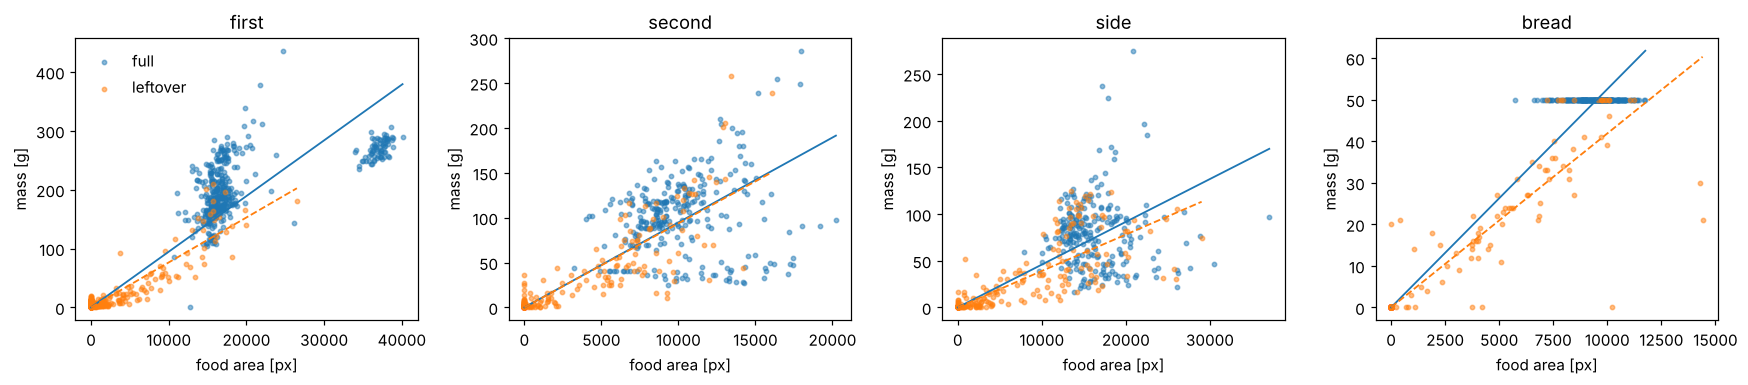

In [13]:
def density_shift_table(items, level="fine", min_n=8):
    g = group_keys(items, level)
    rows = []
    for key in np.unique(g):
        sel = g == key
        if sel.sum() < min_n:
            continue
        a_f, m_f = items.area_full[sel].to_numpy(float), items.mass_full[sel].to_numpy(float)
        a_l, m_l = items.area_left[sel].to_numpy(float), items.mass_left[sel].to_numpy(float)
        d_f, d_l = _ls_origin(a_f, m_f), _ls_origin(a_l, m_l)
        A, M = np.r_[a_f, a_l], np.r_[m_f, m_l]
        pcc = stats.pearsonr(A, M)[0] if A.std() > 0 and M.std() > 0 else np.nan
        rows.append(dict(group=key, n=int(sel.sum()), delta_full=d_f, delta_left=d_l,
                         implied_bias_g=(d_f - d_l) * a_l.mean(),
                         shift=d_l / d_f if d_f else np.nan, abs_log_shift=abs(math.log(d_l / d_f)) if d_f and d_l and d_l > 0 else np.nan,
                         pearson_pooled=pcc))
    return pd.DataFrame(rows).sort_values("abs_log_shift", ascending=False)


shift_tab = density_shift_table(ITEMS, "fine")
RESULTS["density_shift"] = shift_tab
display(shift_tab.head(12))

if len(shift_tab) >= 5 and len(dish_tab):
    m = shift_tab.assign(dish=shift_tab.group).merge(dish_tab[["dish", "MAE_1/Full_%"]], on="dish").dropna(subset=["abs_log_shift", "MAE_1/Full_%"])
    if len(m) >= 5:
        rho, p = stats.spearmanr(m["abs_log_shift"], m["MAE_1/Full_%"])
        print(f"Spearman correlation between |log density-shift| and baseline relative error (n={len(m)} dishes): rho={rho:.2f}, p={p:.3g}")
        m2 = shift_tab.assign(dish=shift_tab.group).merge(dish_tab[["dish", "MAE_1_g"]], on="dish").dropna(subset=["implied_bias_g", "MAE_1_g"])
        rho2, p2 = stats.spearmanr(m2["implied_bias_g"].abs(), m2["MAE_1_g"])
        print(f"Spearman between |implied bias| = |(delta_full - delta_left) * mean leftover area| [g] and baseline MAE-1 [g] (n={len(m2)}): rho={rho2:.2f}, p={p2:.3g}")
        print("A raw |log shift| ignores how much food is actually left; the implied bias in grams does not.")
        print("Caveat: both quantities grow with the amount of leftover food, so part of this correlation is mechanical. Report it as consistent with the density-shift explanation, not as proof.")
        RESULTS["shift_vs_error_spearman"] = pd.DataFrame([dict(metric="abs_log_shift vs MAE_1/Full_%", n=len(m), rho=rho, p=p),
                                                           dict(metric="abs implied_bias_g vs MAE_1_g", n=len(m2), rho=rho2, p=p2)])

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, c in zip(axes, COURSES):
    s = ITEMS[ITEMS.course == c]
    ax.scatter(s.area_full, s.mass_full, s=8, alpha=.5, label="full")
    ax.scatter(s.area_left, s.mass_left, s=8, alpha=.5, label="leftover")
    for col_a, col_m, ls in [("area_full", "mass_full", "-"), ("area_left", "mass_left", "--")]:
        d = _ls_origin(s[col_a].to_numpy(float), s[col_m].to_numpy(float))
        xs = np.linspace(0, s[[col_a]].max().iloc[0], 20)
        ax.plot(xs, d * xs, ls, lw=1.2)
    ax.set_title(c); ax.set_xlabel("food area [px]"); ax.set_ylabel("mass [g]")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 8. RQ2: Should enrollment include a few leftover weighings?

The paper enrolls with *full* plates only, which is the cheapest to weigh, but leftovers follow a different density line for some dishes. For the same total number of weighings `F`, compare:

- `full-only (paper)`: all `F` weighings on full plates;
- `leftover-only`: all `F` on leftover plates;
- `mixed 50/50`: half and half.

Evaluation uses `exclude_train=True` (the enrollment trays are removed from the test set), so a leftover-enrolled method is not tested on its own tray. Differences are reported with a bootstrap CI over enrollment draws.

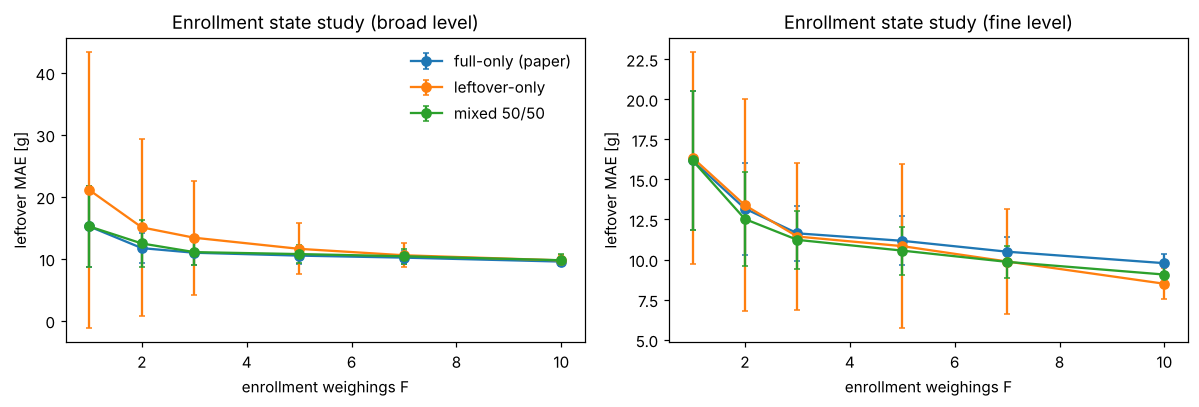

,level,F,comparison,mean_diff,ci_lo,ci_hi,wilcoxon_p
2,broad,3,full-only minus leftover-only,-2.420,-5.464,-0.305,0.230
3,broad,3,full-only minus mixed 50/50,-0.101,-0.358,0.151,0.461
8,broad,10,full-only minus leftover-only,-0.195,-0.449,0.064,0.121
9,broad,10,full-only minus mixed 50/50,-0.218,-0.411,-0.030,0.160
2,fine,3,full-only minus leftover-only,0.200,-1.130,1.249,0.001
3,fine,3,full-only minus mixed 50/50,0.407,0.249,0.551,0.000
8,fine,10,full-only minus leftover-only,1.284,0.947,1.595,0.000
9,fine,10,full-only minus mixed 50/50,0.710,0.565,0.869,0.000


Positive mean_diff = the alternative beats the paper's full-only enrollment. CI covers enrollment randomness only.


In [14]:
def enrollment_state_study(items, level="broad", F_list=(1, 2, 3, 5, 7, 10), R=50, seed=0):
    ests = {"full-only (paper)": est_full, "leftover-only": est_left, "mixed 50/50": est_mixed}
    rows, tests = [], []
    for F in F_list:
        e = aligned(run_enrollment(items, ests, level, F, R, seed + F, exclude_train=True))
        for k, v in e.items():
            runs = mae_runs(v)
            rows.append(dict(level=level, F=F, estimator=k, MAE_g=np.nanmean(runs), sd=np.nanstd(runs)))
        if F >= 2:
            for other in ("leftover-only", "mixed 50/50"):
                r = paired_report(e, "full-only (paper)", other)
                tests.append(dict(level=level, F=F, comparison=f"full-only minus {other}", **r))
    return pd.DataFrame(rows), pd.DataFrame(tests)


state_rows, state_tests = [], []
for lvl in ["broad", "fine"]:
    a, b = enrollment_state_study(ITEMS, lvl, R=R_NEW, seed=SEED)
    state_rows.append(a); state_tests.append(b)
state_curve, state_test = pd.concat(state_rows), pd.concat(state_tests)
RESULTS["enrollment_state_curve"], RESULTS["enrollment_state_tests"] = state_curve, state_test

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, lvl in zip(axes, ["broad", "fine"]):
    s = state_curve[state_curve.level == lvl]
    for k, g in s.groupby("estimator"):
        ax.errorbar(g.F, g.MAE_g, yerr=g.sd, marker="o", capsize=2, label=k)
    ax.set_title(f"Enrollment state study ({lvl} level)"); ax.set_xlabel("enrollment weighings F"); ax.set_ylabel("leftover MAE [g]")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()
display(state_test[state_test.F.isin([3, 10])])
print("Positive mean_diff = the alternative beats the paper's full-only enrollment. CI covers enrollment randomness only.")

## 9. RQ3: The paired before/after estimator

**Idea.** FLIC (and any real canteen with a checkout camera) has the *full-tray image of the same tray*. The paper treats images independently. The paired estimator uses the **fraction remaining** `area_left / area_full`:

`prediction = (area_left / area_full) * served_mass_hat`

where `served_mass_hat = alpha * (delta * area_full) + (1 - alpha) * (mean enrolled full mass)`.

- `alpha = 1` is *identical* to the paper's baseline (algebraically), so the baseline is a special case.
- `alpha = 0` assumes a standard portion size and uses only the remaining fraction.
- In between, it shrinks the per-tray estimate toward the class's standard portion.

**Pre-specified protocol (no peeking at the test set):**
1. Split the days at random into development days and test days (50/50).
2. Choose `alpha` from {0, .25, .5, .75, 1} on the **development** days only (broad level, `F` in {1, 3, 10}).
3. Evaluate baseline versus paired(`alpha*`) on the **held-out test days**, at all three class levels.
4. Repeat for 10 random splits; report mean +/- sd across splits and how often the paired estimator wins.

Note that `alpha = 1` can be selected, in which case the methods tie. That would itself be an honest finding.

done in 2s | alpha selected per split: [0.75, 0.75, 1.0, 1.0, 1.0, 0.75, 1.0, 1.0, 1.0, 1.0]


,level,F,baseline_MAE,paired_MAE,mean_gain_g,sd_gain_g,win_rate,tie_rate,rel_gain_%
0,broad,1,12.405,12.444,-0.038,0.081,0.000,0.700,-0.308
1,broad,3,10.960,11.059,-0.099,0.170,0.000,0.700,-0.907
2,broad,5,10.552,10.690,-0.138,0.225,0.000,0.700,-1.310
3,broad,10,10.065,10.244,-0.179,0.294,0.000,0.700,-1.773
4,fine,1,11.932,11.932,-0.000,0.050,0.200,0.700,-0.001
5,fine,3,11.038,11.028,0.010,0.040,0.200,0.700,0.087
6,fine,5,10.593,10.601,-0.008,0.047,0.100,0.700,-0.074
7,fine,10,10.020,10.012,0.008,0.041,0.200,0.700,0.076
8,none,1,16.451,16.628,-0.177,0.412,0.100,0.700,-1.077
9,none,3,14.587,14.880,-0.292,0.491,0.000,0.700,-2.004


mean_gain_g > 0 means the paired estimator has lower error on held-out days.
Across-split sd is the honest uncertainty here; splits overlap, so treat any p-value as indicative only.


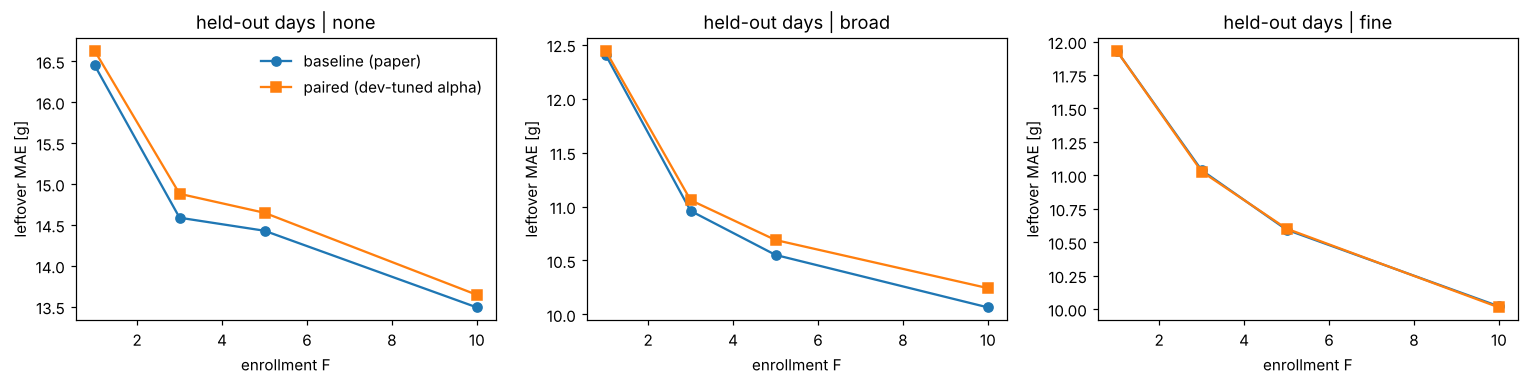

In [15]:
def nested_day_eval(items, alphas=(0.0, 0.25, 0.5, 0.75, 1.0), S=10, R=30, F_sel=(1, 3, 10),
                    F_eval=(1, 3, 5, 10), dev_frac=0.5, seed=0):
    days = np.array(sorted(items.day_id.unique()))
    if len(days) < 4:
        raise ValueError("Need at least 4 distinct days for a dev/test day split.")
    rows, picks = [], []
    for s in range(S):
        rng = np.random.default_rng(seed + s)
        perm = rng.permutation(days)
        dev_days = set(perm[:max(1, int(round(len(days) * dev_frac)))])
        dev = items[items.day_id.isin(dev_days)].reset_index(drop=True)
        tst = items[~items.day_id.isin(dev_days)].reset_index(drop=True)
        ests = {a: make_est_paired(a) for a in alphas}
        score = {a: [] for a in alphas}
        for F in F_sel:
            e = aligned(run_enrollment(dev, ests, "broad", F, R, seed + 100 * s + F, exclude_train=True))
            for a in alphas:
                score[a].append(np.nanmean(mae_runs(e[a])))
        best = min(alphas, key=lambda a: np.nanmean(score[a]))
        picks.append(dict(split=s, alpha_selected=best, n_dev_days=len(dev_days), n_test_days=len(days) - len(dev_days)))
        test_ests = {"baseline (paper)": est_full, "paired (dev-tuned alpha)": make_est_paired(best)}
        for level in ["none", "broad", "fine"]:
            for F in F_eval:
                e = aligned(run_enrollment(tst, test_ests, level, F, R, seed + 10_000 + 100 * s + F, exclude_train=True))
                for name, arr in e.items():
                    rows.append(dict(split=s, level=level, F=F, estimator=name, MAE_g=float(np.nanmean(mae_runs(arr)))))
    return pd.DataFrame(rows), pd.DataFrame(picks)


t0 = time.time()
nested, picks = nested_day_eval(ITEMS, S=N_DAY_SPLITS, R=30, seed=SEED)
RESULTS["paired_nested_raw"], RESULTS["paired_alpha_picks"] = nested, picks
print(f"done in {time.time() - t0:.0f}s | alpha selected per split:", picks.alpha_selected.tolist())

wide = nested.pivot_table(index=["level", "F", "split"], columns="estimator", values="MAE_g").reset_index()
wide["gain_g"] = wide["baseline (paper)"] - wide["paired (dev-tuned alpha)"]
summ = wide.groupby(["level", "F"]).agg(
    baseline_MAE=("baseline (paper)", "mean"), paired_MAE=("paired (dev-tuned alpha)", "mean"),
    mean_gain_g=("gain_g", "mean"), sd_gain_g=("gain_g", "std"),
    win_rate=("gain_g", lambda x: float((x > 1e-9).mean())),
    tie_rate=("gain_g", lambda x: float((x.abs() <= 1e-9).mean()))).reset_index()
summ["rel_gain_%"] = 100 * summ["mean_gain_g"] / summ["baseline_MAE"]
RESULTS["paired_summary"] = summ
display(summ)
print("mean_gain_g > 0 means the paired estimator has lower error on held-out days.")
print("Across-split sd is the honest uncertainty here; splits overlap, so treat any p-value as indicative only.")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
for ax, lvl in zip(axes, ["none", "broad", "fine"]):
    s = summ[summ.level == lvl]
    ax.plot(s.F, s.baseline_MAE, "o-", label="baseline (paper)")
    ax.plot(s.F, s.paired_MAE, "s-", label="paired (dev-tuned alpha)")
    ax.set_title(f"held-out days | {lvl}"); ax.set_xlabel("enrollment F"); ax.set_ylabel("leftover MAE [g]")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**Sensitivity (post-hoc, label it as such in the paper).** The table below shows test-day error for every fixed `alpha`, with no tuning, on all days. It shows *why* the tuned value was chosen. Do not use it to pick `alpha`.

In [16]:
alpha_grid = (0.0, 0.25, 0.5, 0.75, 1.0)
rows = []
for lvl in ["broad", "fine"]:
    for F in (1, 3, 10):
        e = aligned(run_enrollment(ITEMS, {a: make_est_paired(a) for a in alpha_grid}, lvl, F, R_NEW, SEED + F, True))
        for a in alpha_grid:
            rows.append(dict(level=lvl, F=F, alpha=a, MAE_g=float(np.nanmean(mae_runs(e[a])))))
sens = pd.DataFrame(rows).pivot_table(index=["level", "F"], columns="alpha", values="MAE_g")
RESULTS["paired_alpha_sensitivity"] = sens.reset_index()
display(sens)

alpha     0.000  0.250  0.500  0.750  1.000
level F                                    
broad 1  13.313 12.657 12.252 12.090 12.185
      3  12.270 11.518 11.015 10.726 10.637
      10 11.942 11.033 10.327  9.844  9.562
fine  1  11.504 11.398 11.380 11.441 11.580
      3  10.777 10.608 10.507 10.477 10.533
      10  9.756  9.631  9.571  9.594  9.681

## 10. RQ4: Remove the human operator, classify the course automatically

The paper's pipeline needs an operator to say whether each food region is a *first course, second course, side dish, or bread*. The fine dish then follows automatically from the daily menu. Here a lightweight classifier replaces the operator, using only **position, shape and colour** of each connected food region.

- **Splits:** `GroupKFold` by day, so no day is in both train and test.
- **Feature ablation:** position and shape only, versus position, shape and colour.
- **Downstream cost.** Leftover mass is estimated four ways, with `delta` per course fitted on training-fold full plates:
  1. **item-oracle**: course areas from the ground-truth mask (the paper's setting);
  2. **region-oracle**: connected regions with their *true* labels (isolates the effect of merged regions);
  3. **auto**: connected regions with *predicted* labels (the realistic system);
  4. **none**: pooled `delta` (the paper's no-classification baseline).

**Scope note:** the food/no-food mask here is the *ground-truth* one. The paper shows that imperfect automatic food/no-food segmentation barely changes mass error (their Table 9), so this isolates the classification question. State this clearly in your paper.

In [17]:
POS_SHAPE = ["cx", "cy", "bw", "bh", "area_frac", "extent"]
COLOUR = ["mR", "mG", "mB", "sR", "sG", "sB", "mS", "mV", "sS", "sV", "hcos", "hsin"]


def make_clf():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced",
                                  random_state=SEED, n_jobs=-1)


def classification_eval(regions, items, feats, n_splits=5):
    reg = regions[regions.tray_id.isin(items.tray_id)].reset_index(drop=True)
    X, y, g = reg[feats].to_numpy(float), reg["true_course"].to_numpy(), reg["day_id"].astype(str).to_numpy()
    pred = np.empty(len(reg), dtype=object)
    for tr, te in GroupKFold(n_splits=min(n_splits, len(np.unique(g)))).split(X, y, g):
        pred[te] = make_clf().fit(X[tr], y[tr]).predict(X[te])
    out = dict(n_regions=len(reg), accuracy=accuracy_score(y, pred), macro_F1=f1_score(y, pred, average="macro"))
    for st in ("full", "leftover"):
        m = (reg.state == st).to_numpy()
        out[f"acc_{st}"] = accuracy_score(y[m], pred[m]) if m.any() else np.nan
    return out, reg, pred


def downstream_eval(regions, items, feats, n_splits=5):
    reg = regions[regions.tray_id.isin(items.tray_id)].reset_index(drop=True)
    X, y, g = reg[feats].to_numpy(float), reg["true_course"].to_numpy(), reg["day_id"].astype(str).to_numpy()
    rows = []
    for tr, te in GroupKFold(n_splits=min(n_splits, len(np.unique(g)))).split(X, y, g):
        clf = make_clf().fit(X[tr], y[tr])
        p = clf.predict(X[te])
        tr_days, te_days = set(g[tr]), set(g[te])
        tr_items, te_items = items[items.day_id.isin(tr_days)], items[items.day_id.isin(te_days)]
        dens = {c: _ls_origin(s.area_full.to_numpy(float), s.mass_full.to_numpy(float)) for c, s in tr_items.groupby("course")}
        pooled = _ls_origin(tr_items.area_full.to_numpy(float), tr_items.mass_full.to_numpy(float))
        sub = reg.iloc[te]
        left = (sub.state == "leftover").to_numpy()
        rl = sub[left].copy()
        rl["pred_course"] = p[left]
        auto_area = rl.groupby(["tray_id", "pred_course"]).area_px.sum()
        ora_area = rl.groupby(["tray_id", "true_course"]).area_px.sum()
        for it in te_items.itertuples(index=False):
            d = dens.get(it.course, np.nan)
            rows.append(dict(tray_id=it.tray_id, course=it.course, y=it.mass_left,
                             item_oracle=d * it.area_left,
                             region_oracle=d * float(ora_area.get((it.tray_id, it.course), 0.0)),
                             auto=d * float(auto_area.get((it.tray_id, it.course), 0.0)),
                             none=pooled * it.area_left))
    return pd.DataFrame(rows)


if REGIONS is not None and len(REGIONS):
    fs = {"position+shape": POS_SHAPE, "position+shape+colour": POS_SHAPE + COLOUR}
    crow = []
    for name, feats in fs.items():
        r, _, _ = classification_eval(REGIONS, ITEMS_RQ4, feats)
        crow.append(dict(features=name, **r))
    cls_tab = pd.DataFrame(crow)
    RESULTS["course_classifier"] = cls_tab
    display(cls_tab)

    _, reg_used, pred_used = classification_eval(REGIONS, ITEMS_RQ4, POS_SHAPE + COLOUR)
    labs = sorted(set(reg_used.true_course) | set(pred_used))
    cm = pd.DataFrame(confusion_matrix(reg_used.true_course, pred_used, labels=labs), index=[f"true {l}" for l in labs],
                      columns=[f"pred {l}" for l in labs])
    print("Confusion matrix (all regions, out-of-fold by day):")
    display(cm)

    ds = downstream_eval(REGIONS, ITEMS_RQ4, POS_SHAPE + COLOUR)
    ds_rows = []
    for variant in ["item_oracle", "region_oracle", "auto", "none"]:
        ds["abs_err_" + variant] = (ds[variant] - ds["y"]).abs()
        ds_rows.append(dict(variant=variant, MAE_g=ds["abs_err_" + variant].mean(),
                            **{f"MAE_{c}": ds.loc[ds.course == c, "abs_err_" + variant].mean() for c in COURSES}))
    ds_tab = pd.DataFrame(ds_rows)
    RESULTS["downstream_classification_cost"] = ds_tab
    display(ds_tab)
    print("Read: 'auto' versus 'region_oracle' = cost of classification errors; 'region_oracle' versus 'item_oracle' = cost of merged regions.")
else:
    print("RQ4 skipped: needs Route B (images + masks). With Route A there are no region features.")

,features,n_regions,accuracy,macro_F1,acc_full,acc_leftover
0,position+shape,1924,0.638,0.641,0.798,0.454
1,position+shape+colour,1924,0.779,0.775,0.877,0.667


Confusion matrix (all regions, out-of-fold by day):


,pred bread,pred first,pred second,pred side
true bread,196,3,44,7
true first,5,361,74,55
true second,51,42,393,41
true side,2,54,47,549


,variant,MAE_g,MAE_first,MAE_second,MAE_side,MAE_bread
0,item_oracle,9.972,10.871,10.668,14.020,2.135
1,region_oracle,10.195,11.252,10.860,13.839,2.693
2,auto,16.975,18.725,22.450,18.298,4.179
3,none,12.840,8.780,10.670,25.381,5.890


Read: 'auto' versus 'region_oracle' = cost of classification errors; 'region_oracle' versus 'item_oracle' = cost of merged regions.


### RQ4 under data scarcity: few-shot training days

A canteen will not have 22 labelled days. Here the classifier (position, shape and colour) is trained on only `k` days and tested on held-out days, repeated over random day splits. Densities `delta` are fitted on the same `k` training days (pooled density if a course is missing there). **Read:** at which `k` does `auto` beat the `none` baseline, if ever?

,k_days,n_splits,region_accuracy,MAE_auto,MAE_none,MAE_region_oracle,MAE_item_oracle,auto_minus_none_g
0,1,20,0.442,25.955,13.200,12.724,12.530,12.755
1,2,20,0.548,22.042,12.267,11.214,10.995,9.775
2,3,20,0.620,20.428,12.422,10.967,10.744,8.006
3,5,20,0.681,19.964,12.178,10.588,10.362,7.785
4,8,20,0.715,18.605,12.022,10.292,10.060,6.583
5,12,20,0.759,17.627,11.972,10.027,9.804,5.655


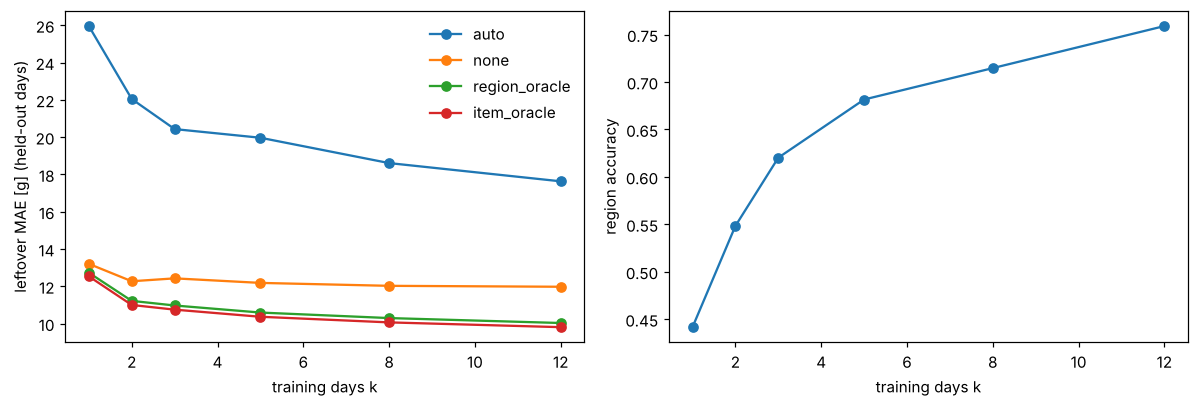

auto_minus_none_g < 0 means the automatic pipeline beats having no classification. Splits share days, so treat differences as indicative.


In [18]:
def fewshot_rq4(regions, items, feats, ks=(1, 2, 3, 5, 8, 12), S=20, test_frac=0.3, seed=0):
    reg = regions[regions.tray_id.isin(items.tray_id)].reset_index(drop=True)
    reg_day = reg.day_id.astype(str).to_numpy()
    days = np.array(sorted(items.day_id.astype(str).unique()))
    rows = []
    for s in range(S):
        rng = np.random.default_rng(seed + s)
        perm = rng.permutation(days)
        n_te = max(2, int(round(len(days) * test_frac)))
        te_days, pool = set(perm[:n_te]), perm[n_te:]
        for k in ks:
            if k > len(pool):
                continue
            tr_days = set(pool[:k])
            trm, tem = np.isin(reg_day, list(tr_days)), np.isin(reg_day, list(te_days))
            if trm.sum() < 5 or len(np.unique(reg.true_course[trm])) < 2:
                continue
            clf = make_clf().fit(reg.loc[trm, feats].to_numpy(float), reg.true_course[trm])
            sub = reg[tem]
            p = clf.predict(sub[feats].to_numpy(float))
            tr_items, te_items = items[items.day_id.isin(tr_days)], items[items.day_id.isin(te_days)]
            dens = {c: _ls_origin(g.area_full.to_numpy(float), g.mass_full.to_numpy(float)) for c, g in tr_items.groupby("course")}
            pooled = _ls_origin(tr_items.area_full.to_numpy(float), tr_items.mass_full.to_numpy(float))
            left = (sub.state == "leftover").to_numpy()
            rl = sub[left].copy()
            rl["pred_course"] = p[left]
            auto_a = rl.groupby(["tray_id", "pred_course"]).area_px.sum()
            ora_a = rl.groupby(["tray_id", "true_course"]).area_px.sum()
            e = {"item_oracle": [], "region_oracle": [], "auto": [], "none": []}
            for it in te_items.itertuples(index=False):
                d = dens.get(it.course, pooled)
                y = it.mass_left
                e["item_oracle"].append(abs(d * it.area_left - y))
                e["region_oracle"].append(abs(d * float(ora_a.get((it.tray_id, it.course), 0.0)) - y))
                e["auto"].append(abs(d * float(auto_a.get((it.tray_id, it.course), 0.0)) - y))
                e["none"].append(abs(pooled * it.area_left - y))
            rows.append(dict(split=s, k_days=k, region_accuracy=accuracy_score(sub.true_course, p),
                             **{f"MAE_{v}": float(np.mean(x)) for v, x in e.items()}))
    return pd.DataFrame(rows)


if REGIONS is not None and len(REGIONS):
    fsr = fewshot_rq4(REGIONS, ITEMS_RQ4, POS_SHAPE + COLOUR, S=20, seed=SEED)
    RESULTS["rq4_fewshot_raw"] = fsr
    fs_sum = fsr.groupby("k_days").agg(n_splits=("split", "size"), region_accuracy=("region_accuracy", "mean"),
                                       MAE_auto=("MAE_auto", "mean"), MAE_none=("MAE_none", "mean"),
                                       MAE_region_oracle=("MAE_region_oracle", "mean"), MAE_item_oracle=("MAE_item_oracle", "mean")).reset_index()
    fs_sum["auto_minus_none_g"] = fs_sum["MAE_auto"] - fs_sum["MAE_none"]
    RESULTS["rq4_fewshot"] = fs_sum
    display(fs_sum)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for col in ["MAE_auto", "MAE_none", "MAE_region_oracle", "MAE_item_oracle"]:
        ax[0].plot(fs_sum.k_days, fs_sum[col], "o-", label=col.replace("MAE_", ""))
    ax[0].set_xlabel("training days k"); ax[0].set_ylabel("leftover MAE [g] (held-out days)"); ax[0].legend(frameon=False)
    ax[1].plot(fs_sum.k_days, fs_sum.region_accuracy, "o-"); ax[1].set_xlabel("training days k"); ax[1].set_ylabel("region accuracy")
    plt.tight_layout(); plt.show()
    print("auto_minus_none_g < 0 means the automatic pipeline beats having no classification. Splits share days, so treat differences as indicative.")
else:
    print("Skipped: needs Route B / FLIC masks.")

## 11. RQ5: Calibrated prediction intervals

A point estimate such as "about 18 g" is of limited use to a canteen manager. What matters is whether the real value is inside the stated range. **Split conformal prediction** wraps any estimator in an interval with a distribution-free coverage guarantee under exchangeability.

**Protocol (repeated 100 times with random day splits):**
1. Split days into *calibration* (40%) and *test* (60%).
2. Enroll `F = 10` full plates per course from calibration days and fit `delta` (the paper's baseline).
3. On the remaining calibration items, compute scores and the `ceil((n+1)(1-a))/n` quantile `q` (here `a = 0.10`, so the target coverage is 90%).
4. Predict `y_hat +/- q` for test-day items and measure the actual coverage and the mean width.

Three variants: global absolute residual, global *normalized* residual (`|err| / (y_hat + 5 g)`, since error grows with mass), and per-course (Mondrian) normalized.

**Caveat:** days are not exchangeable (menus differ), so coverage can drift below the nominal level. That is a finding too, and the per-course coverage shows where it breaks.

In [19]:
def conformal_eval(items, miscov=0.10, F=10, S=100, cal_frac=0.4, eps=5.0, min_cal=20, seed=0):
    days = np.array(sorted(items.day_id.unique()))
    D = arrays(items)
    course, dayarr = items.course.to_numpy(), items.day_id.to_numpy()
    rows = []

    def qhat(scores):
        n = len(scores)
        k = int(np.ceil((n + 1) * (1 - miscov)))
        return np.sort(scores)[min(k, n) - 1]

    for s in range(S):
        rng = np.random.default_rng(seed + s)
        perm = rng.permutation(days)
        cal_days = set(perm[:max(1, int(round(len(days) * cal_frac)))])
        iscal = np.isin(dayarr, list(cal_days))
        delta, enroll = {}, []
        for c in COURSES:
            idx = np.where(iscal & (course == c))[0]
            if len(idx) == 0:
                continue
            tr = rng.permutation(idx)[:min(F, len(idx))]
            enroll.extend(tr.tolist())
            delta[c] = _ls_origin(D["A_f"][tr], D["m_f"][tr])
        yhat = np.array([delta.get(c, np.nan) for c in course]) * D["A_l"]
        y = D["m_l"]
        cal = iscal.copy()
        cal[np.array(enroll, int)] = False
        cal &= np.isfinite(yhat)
        tst = (~iscal) & np.isfinite(yhat)
        if cal.sum() < 10 or tst.sum() < 10:
            continue
        res = np.abs(y - yhat)
        norm = res / (yhat + eps)
        q_abs, q_norm = qhat(res[cal]), qhat(norm[cal])
        q_course = {c: (qhat(norm[cal & (course == c)]) if (cal & (course == c)).sum() >= min_cal else q_norm) for c in COURSES}
        variants = {
            "global | absolute": (np.maximum(yhat - q_abs, 0), yhat + q_abs),
            "global | normalized": (np.maximum(yhat - q_norm * (yhat + eps), 0), yhat + q_norm * (yhat + eps)),
            "per-course | normalized": (None, None),
        }
        qc = np.array([q_course[c] for c in course])
        variants["per-course | normalized"] = (np.maximum(yhat - qc * (yhat + eps), 0), yhat + qc * (yhat + eps))
        for name, (lo, hi) in variants.items():
            cover = (y >= lo) & (y <= hi)
            row = dict(split=s, variant=name, coverage=cover[tst].mean(), width_g=(hi - lo)[tst].mean())
            for c in COURSES:
                m = tst & (course == c)
                row[f"cov_{c}"] = cover[m].mean() if m.any() else np.nan
            rows.append(row)
    return pd.DataFrame(rows)


conf = conformal_eval(ITEMS, S=N_CONFORMAL_SPLITS, seed=SEED)
RESULTS["conformal_raw"] = conf
conf_sum = conf.groupby("variant").agg(
    coverage_mean=("coverage", "mean"), coverage_sd=("coverage", "std"), coverage_min=("coverage", "min"),
    width_g=("width_g", "mean"), **{f"cov_{c}": (f"cov_{c}", "mean") for c in COURSES}).reset_index()
RESULTS["conformal_summary"] = conf_sum
display(conf_sum)
print("Target coverage: 0.90. Compare coverage_mean with the target, and look at the per-course columns for under-coverage.")

,variant,coverage_mean,coverage_sd,coverage_min,width_g,cov_first,cov_second,cov_side,cov_bread
0,global | absolute,0.892,0.036,0.802,40.659,0.897,0.870,0.806,0.987
1,global | normalized,0.901,0.039,0.776,46.861,0.797,0.929,0.947,0.990
2,per-course | normalized,0.892,0.036,0.765,44.440,0.898,0.893,0.875,0.898


Target coverage: 0.90. Compare coverage_mean with the target, and look at the per-course columns for under-coverage.


## 12. Save everything and record the environment

All tables go to `flic_outputs/`. Save the notebook with outputs alongside them, so reviewers can re-run it.

In [20]:
for name, df in RESULTS.items():
    df.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
env = dict(data_mode=DATA_MODE, seed=SEED, python=platform.python_version(), numpy=np.__version__,
           pandas=pd.__version__, n_items_analysis=int(len(ITEMS)), n_trays=int(ITEMS.tray_id.nunique()),
           n_days=int(ITEMS.day_id.nunique()), R_REPRO=R_REPRO, R_NEW=R_NEW, N_DAY_SPLITS=N_DAY_SPLITS,
           N_CONFORMAL_SPLITS=N_CONFORMAL_SPLITS, route=ROUTE if DATA_MODE == "real" else "synthetic",
           mask_labels={str(k): v for k, v in MASK_LABELS.items()})
(OUTPUT_DIR / "environment.json").write_text(json.dumps(env, indent=2))
print("Saved:", sorted(p.name for p in OUTPUT_DIR.iterdir()))
if DATA_MODE == "synthetic":
    print("\nREMINDER: these are SYNTHETIC results from the pipeline self-test. Switch DATA_MODE to 'real' and re-run.")

Saved: ['cleaning_flow.csv', 'conformal_raw.csv', 'conformal_summary.csv', 'course_classifier.csv', 'data_quality_mask_vs_csv.csv', 'density_shift.csv', 'downstream_classification_cost.csv', 'enrollment_state_curve.csv', 'enrollment_state_tests.csv', 'environment.json', 'items_by_course.csv', 'paired_alpha_picks.csv', 'paired_alpha_sensitivity.csv', 'paired_nested_raw.csv', 'paired_summary.csv', 'per_dish_error.csv', 'repro_paper_protocol.csv', 'repro_strict_protocol.csv', 'rq4_fewshot.csv', 'rq4_fewshot_raw.csv', 'shift_vs_error_spearman.csv']


## 13. Turning the results into a paper

**Claims you may make, depending on what the real data show.** (Write the paper around the evidence, not the other way round.)

| Outcome | Honest framing |
|---|---|
| Paired estimator wins on most held-out splits, especially for second courses | "Exploiting the before/after pair reduces few-shot error by X% (95% range across splits), with one hyperparameter tuned on separate days." |
| Paired estimator ties the baseline (selected `alpha = 1`) | "The area-only baseline is hard to beat; pairing does not help because ..." Use the density-shift analysis to explain why. |
| Leftover or mixed enrollment beats full-only | "Weighing just k leftover plates during setup reduces error by X g, at the cost of ..." A practical recommendation for canteens. |
| Auto classification close to region-oracle | "Operator-free pipeline loses only X g MAE." Show the confusion matrix and which classes are confused. |
| Conformal coverage near 90% | "Calibrated intervals are feasible." If coverage is below target for some courses, report that as a limitation of exchangeability across days. |

**Recommended paper structure:** Introduction (food waste, FLIC gap) -> Related work (cite FLIC, UNIMIB2015, Nutrition5k, LeFood-set) -> Dataset and protocol (reproduced, with the leakage check) -> Methods (digital density; paired estimator; enrollment states; region classifier; conformal) -> Experiments (RQ0-RQ5 tables above) -> Discussion (density shift, heterogeneous dishes, non-edible fractions such as bones) -> Limitations -> Conclusion.

**Limitations you must state:** single site and fixed menu; 1,166 items from 401 tray pairs on 22 days of one canteen; ground-truth food/no-food masks used in RQ4; classification features are hand-designed; mass labels are per plate and tray-level conclusions are not tested; second-course and side dishes served on one plate (111 trays) are excluded, as in the paper, and RQ4 uses only the 290 unmixed trays; results depend on camera geometry (fixed overhead camera, 65 cm in the paper).

**Before submitting:** (1) confirm the dataset's license and terms of use; (2) cite FLIC properly; (3) archive this notebook and the `flic_outputs/` folder; (4) have a co-author re-run it on a clean machine; (5) never present synthetic output.

**Ideas for a stronger second version:** frozen DINOv2 embeddings per region for classification; a mixture-density model that separates edible mass from bone; volume cues via monocular depth estimation; multi-site validation.